# homework 3.2: limits, derivatives, and Taylor's theorem

Aashir Javed | MAT 422

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aaxhirrr/mat-422-fall-2026/blob/AASHIR/hw3-2/HW3.2/HW3_2_limits_derivatives_taylor.ipynb)

These three ideas build on each other. A limit describes what happens near a point, a derivative measures local change, and a Taylor polynomial uses derivatives to approximate a function. I start with simple one-variable examples, then show how the same ideas work with two inputs.

We can run the notebook from the top with **Runtime > Run all** in Colab. The tables and plots illustrate the calculations; the algebra explains why the results hold.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

## 3.2.1. limits and continuity

The statement $\lim_{x\to a}f(x)=L$ means that for every $\epsilon>0$, we can choose $\delta>0$ so that $0<|x-a|<\delta$ implies $|f(x)-L|<\epsilon$. We look near the point, not necessarily at the point itself. Continuity adds the requirement that the function is defined there and the limit equals $f(a)$.

For example,

$$f(x)=\frac{x^2-1}{x-1}=x+1\quad\text{when }x\ne1.$$

Both sides approach 2 as $x$ approaches 1, although the original fraction is undefined at 1. Defining $f(1)=2$ fills the hole and makes it continuous. We can also justify the limit directly: $|f(x)-2|=|x-1|$, so choosing $\delta=\epsilon$ works.

distance       from left      from right
  0.1000       1.900000       2.100000
  0.0100       1.990000       2.010000
  0.0010       1.999000       2.001000
  0.0001       1.999900       2.000100


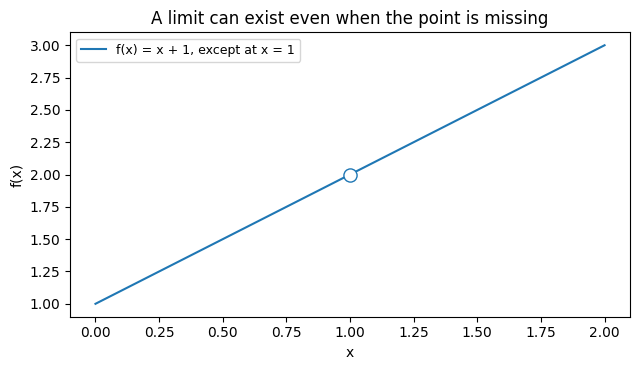

In [2]:
def hole_function(x):
    return (x**2 - 1) / (x - 1)

steps = np.array([0.1, 0.01, 0.001, 0.0001])
left_values = hole_function(1 - steps)
right_values = hole_function(1 + steps)
print("distance       from left      from right")
for h, left, right in zip(steps, left_values, right_values):
    print(f"{h:8.4f}       {left:.6f}       {right:.6f}")

x_plot = np.linspace(0, 2, 201)
plt.figure(figsize=(6.5, 3.8))
plt.plot(x_plot, x_plot + 1, label="f(x) = x + 1, except at x = 1")
plt.scatter([1], [2], facecolors="white", edgecolors="tab:blue", s=90, zorder=3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("A limit can exist even when the point is missing")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

The left-hand values rise toward 2 and the right-hand values fall toward 2. The open circle marks the missing value. The table supports the limit, but the cancellation above is what establishes it.

### a limit that depends on the path

For functions of a vector, we replace distance $|x-a|$ with the norm $\|\mathbf{x}-\mathbf{a}\|$. A limit must be the same along every path toward the point.

Consider $g(x,y)=xy/(x^2+y^2)$ away from the origin, with $g(0,0)=0$. Along $y=0$, the value is 0. Along $y=x$, it is $1/2$ for every nonzero $x$. The two paths disagree, so the limit at the origin does not exist. Giving the function a value there cannot fix that discontinuity. Agreement along just a few paths would not be enough to prove a limit exists, either.

In [3]:
def path_function(x, y):
    return x * y / (x**2 + y**2)

t = np.array([0.1, 0.01, 0.001, 0.0001])
axis_path = path_function(t, np.zeros_like(t))
diagonal_path = path_function(t, t)
print("distance       along y = 0   along y = x")
for value, axis, diagonal in zip(t, axis_path, diagonal_path):
    print(f"{value:8.4f}       {axis:.6f}       {diagonal:.6f}")

distance       along y = 0   along y = x
  0.1000       0.000000       0.500000
  0.0100       0.000000       0.500000
  0.0010       0.000000       0.500000
  0.0001       0.000000       0.500000


## 3.2.2. derivatives

The derivative is the limit of a difference quotient:

$$f'(a)=\lim_{h\to0}\frac{f(a+h)-f(a)}{h}.$$

For $f(x)=x^3$, the power rule gives $f'(x)=3x^2$, so the slope at $a=1$ is 3. We can compare forward and centered differences:

$$D_h^+f(1)=3+3h+h^2,\qquad
D_h^0f(1)=\frac{f(1+h)-f(1-h)}{2h}=3+h^2.$$

Here the forward error is of order $h$, while the centered error is of order $h^2$. That makes the centered estimate more accurate for the same small step. However, extremely small steps can cause floating-point cancellation, so smaller is not always better on a computer.

h            forward          centered
1e-01          3.31000000       3.01000000
1e-02          3.03010000       3.00010000
1e-03          3.00300100       3.00000100
1e-04          3.00030001       3.00000001
1e-05          3.00003000       3.00000000
1e-06          3.00000300       3.00000000


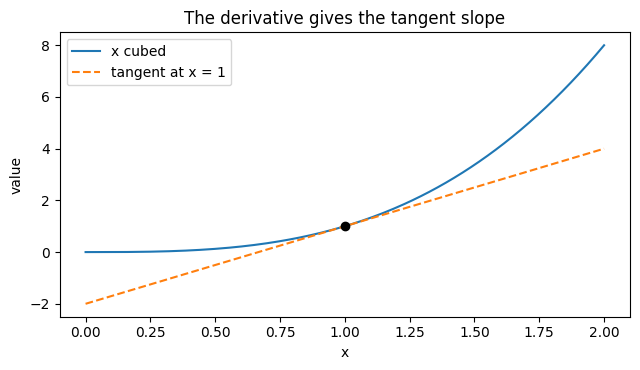

In [4]:
def cubic(x):
    return x**3

h_values = 10.0**(-np.arange(1, 7))
forward = (cubic(1 + h_values) - cubic(1)) / h_values
centered = (cubic(1 + h_values) - cubic(1 - h_values)) / (2 * h_values)
print("h            forward          centered")
for h, fwd, mid in zip(h_values, forward, centered):
    print(f"{h:.0e}          {fwd:.8f}       {mid:.8f}")

x_plot = np.linspace(0, 2, 250)
plt.figure(figsize=(6.5, 3.8))
plt.plot(x_plot, cubic(x_plot), label="x cubed")
plt.plot(x_plot, 1 + 3 * (x_plot - 1), "--", label="tangent at x = 1")
plt.scatter([1], [1], color="black", zorder=3)
plt.xlabel("x")
plt.ylabel("value")
plt.title("The derivative gives the tangent slope")
plt.legend()
plt.tight_layout()
plt.show()

Both estimates approach 3, and the centered estimate is closer for the steps in the table. The tangent line is $1+3(x-1)$: it matches the cubic's value and slope at 1, but the curves separate farther away.

Differentiability implies continuity, but continuity does not guarantee differentiability. The function $|x|$ is continuous at zero because $||x|-0|=|x|$. Its left-hand slope is $-1$ and its right-hand slope is $1$, so there is no single derivative there.

In [5]:
h = np.array([0.1, 0.01, 0.001])
abs_left = (np.abs(-h) - 0) / (-h)
abs_right = (np.abs(h) - 0) / h
print("left slopes for abs(x):", abs_left)
print("right slopes for abs(x):", abs_right)

left slopes for abs(x): [-1. -1. -1.]
right slopes for abs(x): [1. 1. 1.]


### partial derivatives, the gradient, and the chain rule

For $q(x,y)=x^2+xy+2y^2$, the partial derivatives hold the other input fixed:

$$\nabla q(x,y)=\begin{bmatrix}2x+y\\x+4y\end{bmatrix},
\qquad H_q=\begin{bmatrix}2&1\\1&4\end{bmatrix}.$$

The gradient collects the first partial derivatives; the Hessian collects the second partial derivatives. At $\mathbf{a}=(1,2)$, the gradient is $(4,9)$. For a unit direction $\mathbf{u}=(3/5,4/5)$, the directional derivative is $\nabla q(\mathbf{a})^T\mathbf{u}=9.6$.

This is also the chain rule along the path $\mathbf{r}(t)=\mathbf{a}+t\mathbf{u}$: the derivative of $q(\mathbf{r}(t))$ at zero equals $\nabla q(\mathbf{a})^T\mathbf{r}'(0)$. This formula applies here because the polynomial is differentiable. Merely having partial derivatives is not enough in general: the earlier discontinuous function $g$ has both partial derivatives equal to zero at the origin, but it is not differentiable there.

In [6]:
def quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2

a = np.array([1.0, 2.0])
gradient = np.array([2*a[0] + a[1], a[0] + 4*a[1]])
hessian = np.array([[2.0, 1.0], [1.0, 4.0]])
direction = np.array([3.0, 4.0]) / 5
small_step = 1e-5
partial_estimates = []
for coordinate in np.eye(2):
    estimate = (quadratic(a + small_step * coordinate)
                - quadratic(a - small_step * coordinate)) / (2 * small_step)
    partial_estimates.append(estimate)
directional_estimate = (quadratic(a + small_step * direction)
                       - quadratic(a - small_step * direction)) / (2 * small_step)
print("gradient from the formula:", gradient)
print("gradient from small steps:", np.array(partial_estimates))
print(f"directional derivative from gradient: {gradient @ direction:.6f}")
print(f"directional derivative from small steps: {directional_estimate:.6f}")

gradient from the formula: [4. 9.]
gradient from small steps: [4. 9.]
directional derivative from gradient: 9.600000
directional derivative from small steps: 9.600000


The numerical partial derivatives match $(4,9)$, and both directional calculations give 9.6. The direction has length 1, so this is a rate of change per unit distance along that direction, not just an arbitrary change in both inputs.

## 3.2.3. Taylor's theorem

If $f$ has continuous derivatives through order $n+1$ on an interval containing $a$ and $x$, then

$$f(x)=T_n(x)+R_n(x),\qquad
T_n(x)=\sum_{k=0}^n\frac{f^{(k)}(a)}{k!}(x-a)^k.$$

The Lagrange remainder is

$$R_n(x)=\frac{f^{(n+1)}(\xi)}{(n+1)!}(x-a)^{n+1}$$

for some $\xi$ between $a$ and $x$. If $|f^{(n+1)}|\le M$ throughout that interval, then $|R_n(x)|\le M|x-a|^{n+1}/(n+1)!$. The bound is a guarantee under these assumptions, not the exact error.

For $e^x$ centered at zero, every derivative at zero is 1. This gives $T_n(x)=\sum_{k=0}^n x^k/k!$. Between zero and a chosen $x$, we can take $M=e^{\max(0,x)}$.

In [7]:
def exp_taylor(x, degree):
    # Each pass adds one more term to the polynomial.
    total = np.zeros_like(np.asarray(x, dtype=float))
    for k in range(degree + 1):
        total = total + np.asarray(x)**k / math.factorial(k)
    return total

degrees = [1, 2, 4, 6]
target = 0.5
taylor_errors = []
taylor_bounds = []
print("degree      approximation       error           bound")
for degree in degrees:
    approximation = float(exp_taylor(target, degree))
    error = abs(np.exp(target) - approximation)
    bound = np.exp(max(0, target)) * abs(target)**(degree + 1) / math.factorial(degree + 1)
    taylor_errors.append(error)
    taylor_bounds.append(bound)
    print(f"{degree:3d}         {approximation:.8f}        {error:.3e}       {bound:.3e}")

degree      approximation       error           bound
  1         1.50000000        1.487e-01       2.061e-01
  2         1.62500000        2.372e-02       3.435e-02
  4         1.64843750        2.838e-04       4.294e-04
  6         1.64871962        1.653e-06       2.556e-06


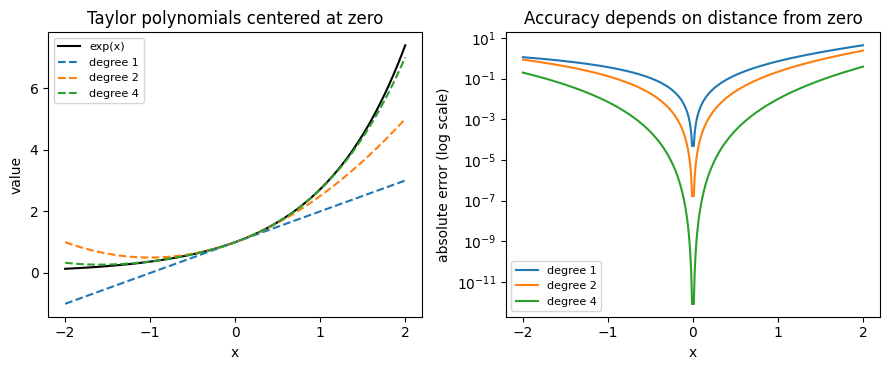

In [8]:
x_plot = np.linspace(-2, 2, 401)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].plot(x_plot, np.exp(x_plot), color="black", label="exp(x)")
for degree in [1, 2, 4]:
    approximation = exp_taylor(x_plot, degree)
    axes[0].plot(x_plot, approximation, "--", label=f"degree {degree}")
    # The exact zero error at the center cannot appear on a log scale.
    error = np.abs(np.exp(x_plot) - approximation)
    axes[1].semilogy(x_plot, np.where(error > 0, error, np.nan), label=f"degree {degree}")
axes[0].set(xlabel="x", ylabel="value", title="Taylor polynomials centered at zero")
axes[1].set(xlabel="x", ylabel="absolute error (log scale)", title="Accuracy depends on distance from zero")
for axis in axes:
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

At $x=0.5$, the degree-4 approximation is about 1.6484375, compared with $e^{0.5}\approx1.6487213$. Its error is about $2.84\times10^{-4}$, below the bound of about $4.29\times10^{-4}$. In this example, adding terms improves the approximation at the target. A fixed-degree polynomial is generally more useful near its center; it is not an exact replacement for the function everywhere.

### the two-variable version

For a smooth function of a vector and a small displacement $\mathbf{d}$,

$$f(\mathbf{a}+\mathbf{d})=f(\mathbf{a})+\nabla f(\mathbf{a})^T\mathbf{d}
+\frac12\mathbf{d}^TH_f(\mathbf{a})\mathbf{d}+O(\|\mathbf{d}\|^3),$$

provided the third derivatives are bounded near the point. The first-order part is a tangent-plane approximation. The Hessian term adds curvature. For our quadratic $q$, all third derivatives are zero, so the second-order formula is exact for every displacement.

In [9]:
displacement = np.array([0.1, -0.2])
exact_value = quadratic(a + displacement)
linear_value = quadratic(a) + gradient @ displacement
second_order_value = linear_value + 0.5 * displacement @ hessian @ displacement
print(f"actual value: {exact_value:.6f}")
print(f"first-order approximation: {linear_value:.6f}")
print(f"second-order approximation: {second_order_value:.6f}")
print(f"first-order error: {abs(exact_value - linear_value):.6f}")

# Moving less far from the center makes the linear error smaller.
scales = np.array([1.0, 0.5, 0.25])
linear_errors = []
for scale in scales:
    d = scale * displacement
    error = abs(quadratic(a + d) - (quadratic(a) + gradient @ d))
    linear_errors.append(error)
    print(f"step scale {scale:.2f}, linear error {error:.6f}")

actual value: 9.670000
first-order approximation: 9.600000
second-order approximation: 9.670000
first-order error: 0.070000
step scale 1.00, linear error 0.070000
step scale 0.50, linear error 0.017500
step scale 0.25, linear error 0.004375


The linear estimate is 9.6, while the actual value is 9.67. The Hessian term contributes the missing 0.07. Halving the displacement reduces the linear error by a factor of four here because that omitted term is quadratic in the displacement. The second-order estimate matches exactly apart from floating-point rounding.

## quick checks

These checks compare the computed values with the algebra above. The tables alone do not prove limits or differentiability, and testing a few Taylor errors does not replace the theorem's assumptions.

In [10]:
checks = {
    "left and right limit values match the algebra": np.allclose(left_values, 2 - steps) and np.allclose(right_values, 2 + steps),
    "two paths have different limits": np.allclose(axis_path, 0) and np.allclose(diagonal_path, 0.5),
    "centered difference approaches 3": np.isclose(centered[-1], 3, atol=1e-7),
    "centered error matches h squared": np.allclose(centered[:3] - 3, h_values[:3]**2, atol=1e-10),
    "absolute value has unequal one-sided slopes": np.allclose(abs_left, -1) and np.allclose(abs_right, 1),
    "gradient matches numerical partials": np.allclose(partial_estimates, gradient),
    "direction is a unit vector": np.isclose(np.linalg.norm(direction), 1),
    "directional derivative matches chain rule": np.isclose(directional_estimate, gradient @ direction),
    "Taylor errors satisfy the bounds": np.all(np.array(taylor_errors) <= np.array(taylor_bounds) + 1e-14),
    "Taylor polynomials match exp at zero": all(np.isclose(exp_taylor(0, n), 1) for n in degrees),
    "second-order quadratic expansion is exact": np.isclose(second_order_value, exact_value),
    "halving the step quarters the linear error": np.allclose(np.array(linear_errors)[1:] / np.array(linear_errors)[:-1], 0.25),
}
for label, passed in checks.items():
    print(f"{label}: {bool(passed)}")
assert all(checks.values()), "one of the checks needs another look"

left and right limit values match the algebra: True
two paths have different limits: True
centered difference approaches 3: True
centered error matches h squared: True
absolute value has unequal one-sided slopes: True
gradient matches numerical partials: True
direction is a unit vector: True
directional derivative matches chain rule: True
Taylor errors satisfy the bounds: True
Taylor polynomials match exp at zero: True
second-order quadratic expansion is exact: True
halving the step quarters the linear error: True


## what I took from this

A function's value at one point and its behavior near that point are different questions. Derivatives use limits to turn nearby changes into a slope, but even a continuous function can have a corner where that slope does not exist. We can then use derivatives to build local approximations. What matters with Taylor's theorem is not only writing down the polynomial, but also knowing where the approximation is useful and how large the error can be.

- AI use note: I had help from Codex in refining the code (not completely writing it), refining the latex of the report, and pushing it to GitHub. Other than that, the intial psuedocode/boilerplates, logic, and the report is still drafted by me. I ran every cell and reviewed the math and explanations before submitting.